<a href="https://colab.research.google.com/github/alexbedoni95-cpu/Analisi-Climatica-UE-e-Modellazione-Predittiva-2035-Progetto-Finale-EEA-/blob/main/Progetto_finale_aulab_parte_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

### 1. Caricamento ed Esplorazione dei Dati

Per prima cosa, carichiamo il file `CO2_Emissions.csv` in un DataFrame pandas e diamo un'occhiata alle prime righe e alle informazioni generali.

In [ ]:
# Carica il dataset delle emissioni di CO2
df_co2 = pd.read_csv('/content/CO2_Emissions.csv')

# Mostra le prime 5 righe del DataFrame
display(df_co2.head())

# Mostra le informazioni sul DataFrame per controllare tipi di dati e valori nulli
display(df_co2.info())

,Country,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Albania,3101.66,5166.7,3311.06,3235.47,3500.49,3477.42,3341.56,3426.64,4139.06,...,5942.57,5942.57,5942.56,5942.57,5942.56,8715.51,5280.94,5239.62,9151.29,8798.25
2,Algeria,NaN,NaN,NaN,NaN,63705.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Antigua and Barbuda,288.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191 entries, 0 to 190
Data columns (total 35 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  190 non-null    object 
 1   1990     90 non-null     float64
 2   1991     65 non-null     float64
 3   1992     67 non-null     float64
 4   1993     70 non-null     float64
 5   1994     152 non-null    float64
 6   1995     78 non-null     float64
 7   1996     71 non-null     float64
 8   1997     72 non-null     float64
 9   1998     74 non-null     float64
 10  1999     70 non-null     float64
 11  2000     150 non-null    float64
 12  2001     70 non-null     float64
 13  2002     74 non-null     float64
 14  2003     74 non-null     float64
 15  2004     76 non-null     float64
 16  2005     90 non-null     float64
 17  2006     78 non-null     float64
 18  2007     71 non-null     float64
 19  2008     70 non-null     float64
 20  2009     68 non-null     float64
 21  2010     89 non-

None

### 2. Pulizia e Preparazione dei Dati

Per questo task, ci concentreremo sulle emissioni di CO2 per i paesi dell'Unione Europea. Definiamo un elenco di paesi membri dell'UE e filtriamo il DataFrame. Successivamente, aggregheremo i dati per anno per ottenere le emissioni totali dell'UE.

In [ ]:
# Elenco dei paesi membri dell'Unione Europea (basato sui membri attuali)
eu_countries = [
    'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark',
    'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland', 'Italy',
    'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Poland', 'Portugal',
    'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden'
]

# Filtra il DataFrame per i paesi dell'UE
df_eu_co2 = df_co2[df_co2['Country'].isin(eu_countries)].copy()

# Poiché i dati sono in formato 'value for year', faremo un melt per un formato più utile
# Identifichiamo le colonne degli anni (escludendo 'Country' e 'Country Code' - not present)
year_columns = [col for col in df_eu_co2.columns if str(col).isdigit()]

# Trasformiamo il DataFrame dal formato wide a long
df_eu_co2_long = df_eu_co2.melt(id_vars=['Country'],
                                 value_vars=year_columns,
                                 var_name='Year',
                                 value_name='CO2 Emissions (kt)')

# Converti la colonna 'Year' in tipo numerico
df_eu_co2_long['Year'] = pd.to_numeric(df_eu_co2_long['Year'])

# Gestione dei valori mancanti: Se ci sono NaN nelle emissioni, possiamo riempirli con 0 o la media,
# ma per le emissioni di CO2, 0 potrebbe essere più appropriato se un anno non ha dati.
# Per semplicità, li riempiremo con 0 per ora, ma si potrebbe considerare un'interpolazione.
df_eu_co2_long['CO2 Emissions (kt)'] = df_eu_co2_long['CO2 Emissions (kt)'].fillna(0)

# Aggregare le emissioni per anno per tutti i paesi dell'UE
eu_total_co2_yearly = df_eu_co2_long.groupby('Year')['CO2 Emissions (kt)'].sum().reset_index()

# Visualizza i dati aggregati
display(eu_total_co2_yearly.head())
display(eu_total_co2_yearly.tail())

# Verifichiamo il range degli anni disponibili
print(f"Anni disponibili: {eu_total_co2_yearly['Year'].min()} - {eu_total_co2_yearly['Year'].max()}")

,Year,CO2 Emissions (kt)
0,1990,3707465.45
1,1991,3662130.20
2,1992,3540244.72
3,1993,3476460.67
4,1994,3468594.07


,Year,CO2 Emissions (kt)
29,2019,2560869.70
30,2020,1514889.96
31,2021,1484480.29
32,2022,2688913.20
33,2023,2333945.40


Anni disponibili: 1990 - 2023


### 3. Visualizzazione dei Dati

Visualizziamo l'andamento delle emissioni totali di CO2 per i paesi dell'UE nel corso degli anni per identificare eventuali trend.

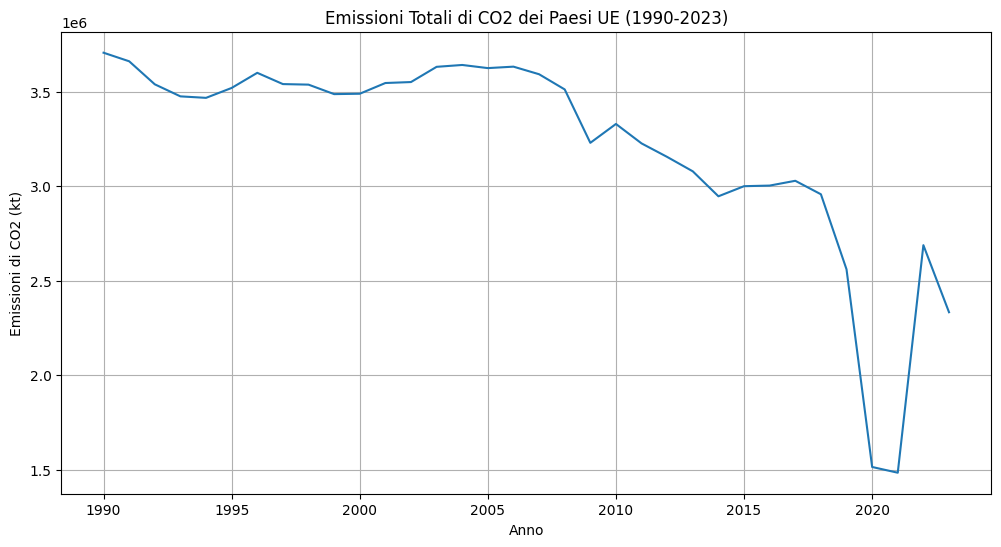

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=eu_total_co2_yearly, x='Year', y='CO2 Emissions (kt)')
plt.title('Emissioni Totali di CO2 dei Paesi UE (1990-2023)')
plt.xlabel('Anno')
plt.ylabel('Emissioni di CO2 (kt)')
plt.grid(True)
plt.show()

### 4. Preparazione dei Dati per i Modelli

Prima di costruire i modelli, divideremo i dati in set di training e testing. Useremo gli anni fino al 2020 per il training e gli anni successivi per il testing. Scaleremo anche i dati per i modelli basati su regressione e LSTM.

In [ ]:
# Definisci le feature (X) e il target (y)
X = eu_total_co2_yearly[['Year']]
y = eu_total_co2_yearly['CO2 Emissions (kt)']

# Split dei dati in training e testing (es: training fino al 2020, testing dal 2021 in poi)
# Troviamo l'ultimo anno nel dataset per definire il cutoff
max_year = X['Year'].max()

# Determina l'anno di cutoff per il training (es. 2020)
training_cutoff_year = 2020

X_train = X[X['Year'] <= training_cutoff_year]
y_train = y[X['Year'] <= training_cutoff_year]
X_test = X[X['Year'] > training_cutoff_year]
y_test = y[X['Year'] > training_cutoff_year]

# Per i modelli di regressione, abbiamo bisogno di array numpy
X_train_np = X_train.values.reshape(-1, 1)
y_train_np = y_train.values
X_test_np = X_test.values.reshape(-1, 1)
y_test_np = y_test.values

print(f"Dimensioni dei dati di training: X={X_train_np.shape}, y={y_train_np.shape}")
print(f"Dimensioni dei dati di testing: X={X_test_np.shape}, y={y_test_np.shape}")

Dimensioni dei dati di training: X=(31, 1), y=(31,)
Dimensioni dei dati di testing: X=(3, 1), y=(3,)


### 8. Modello LSTM

Costruiamo un modello LSTM (Long Short-Term Memory), una rete neurale ricorrente particolarmente adatta per le serie temporali, per prevedere le emissioni di CO2. Useremo i dati scalati e le sequenze create nel passaggio precedente.

In [ ]:
# Costruisci il modello LSTM
lstm_model = Sequential()
lstm_model.add(LSTM(50, activation='relu', input_shape=(look_back, 1)))
lstm_model.add(Dense(1))
lstm_model.compile(optimizer='adam', loss='mean_squared_error')

# Addestra il modello
history = lstm_model.fit(X_train_lstm, y_train_lstm, epochs=100, batch_size=1, verbose=0)

# Effettua previsioni sui dati di test
y_pred_lstm_scaled = lstm_model.predict(X_test_lstm)

# Inverti la scalatura per ottenere i valori reali
y_pred_lstm = scaler.inverse_transform(y_pred_lstm_scaled)

# Valuta il modello
mse_lstm = mean_squared_error(scaler.inverse_transform(y_test_lstm.reshape(-1, 1)), y_pred_lstm)
print(f"Mean Squared Error (LSTM): {mse_lstm:.2f}")

# --- Previsione futura con LSTM fino al 2035 ---
# Partiamo dall'ultimo dato disponibile nel training set
last_train_sequence = X_train_lstm[-1]

# Crea una lista per memorizzare le previsioni future
future_predictions_scaled = []
current_sequence = last_train_sequence

# Prevedi fino al 2035
for i in range(2021, 2036):
    # Prevedi il prossimo valore
    next_prediction_scaled = lstm_model.predict(current_sequence.reshape(1, look_back, 1), verbose=0)[0, 0]
    future_predictions_scaled.append(next_prediction_scaled)

    # Aggiorna la sequenza corrente per la prossima previsione
    # Rimuovi il primo elemento e aggiungi la nuova previsione alla fine
    current_sequence = np.append(current_sequence[1:], next_prediction_scaled)
    current_sequence = current_sequence.reshape(look_back, 1) # Mantiene la forma corretta

# Inverti la scalatura delle previsioni future
future_predictions = scaler.inverse_transform(np.array(future_predictions_scaled).reshape(-1, 1))

# Crea un DataFrame per le previsioni LSTM
df_pred_lstm = pd.DataFrame({
    'Year': np.arange(2021, 2036),
    'CO2 Emissions (kt)': future_predictions.flatten()
})

# Visualizza i risultati
plt.figure(figsize=(14, 7))
sns.lineplot(data=eu_total_co2_yearly, x='Year', y='CO2 Emissions (kt)', label='Dati Storici UE')
sns.lineplot(data=df_pred_linear, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Lineare', linestyle='--')
sns.lineplot(data=df_pred_poly, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Polinomiale (grado 2)', linestyle='-.', color='green')
sns.lineplot(data=df_pred_lstm, x='Year', y='CO2 Emissions (kt)', label='Previsione LSTM', linestyle=':', color='purple')
plt.title('Previsione Emissioni CO2 UE con Regressione Lineare, Polinomiale e LSTM (fino al 2035)')
plt.xlabel('Anno')
plt.ylabel('Emissioni di CO2 (kt)')
plt.grid(True)
plt.legend()
plt.show()

NameError: name 'look_back' is not defined

### 9. Riepilogo e Confronto dei Modelli

Per concludere, possiamo confrontare le previsioni dei tre modelli e valutare quale sia il più adatto per questo tipo di serie storica.

In [ ]:
print("--- Confronto MSE sui dati di test ---")
print(f"Regressione Lineare MSE: {mse_linear:.2f}")
print(f"Regressione Polinomiale (grado 2) MSE: {mse_poly:.2f}")
print(f"LSTM MSE: {mse_lstm:.2f}")

plt.figure(figsize=(14, 7))
sns.lineplot(data=eu_total_co2_yearly, x='Year', y='CO2 Emissions (kt)', label='Dati Storici UE')
sns.lineplot(data=df_pred_linear, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Lineare', linestyle='--')
sns.lineplot(data=df_pred_poly, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Polinomiale (grado 2)', linestyle='-.', color='green')
sns.lineplot(data=df_pred_lstm, x='Year', y='CO2 Emissions (kt)', label='Previsione LSTM', linestyle=':', color='purple')
plt.title('Confronto Previsioni Emissioni CO2 UE (fino al 2035)')
plt.xlabel('Anno')
plt.ylabel('Emissioni di CO2 (kt)')
plt.grid(True)
plt.legend()
plt.show()

--- Confronto MSE sui dati di test ---
Regressione Lineare MSE: 575271420638.17


NameError: name 'mse_poly' is not defined

### 5. Modello di Regressione Lineare

Implementiamo un modello di regressione lineare per prevedere le emissioni di CO2. Addestreremo il modello sui dati di training e poi valuteremo la sua performance sui dati di test.

Mean Squared Error (Regressione Lineare): 575271420638.17


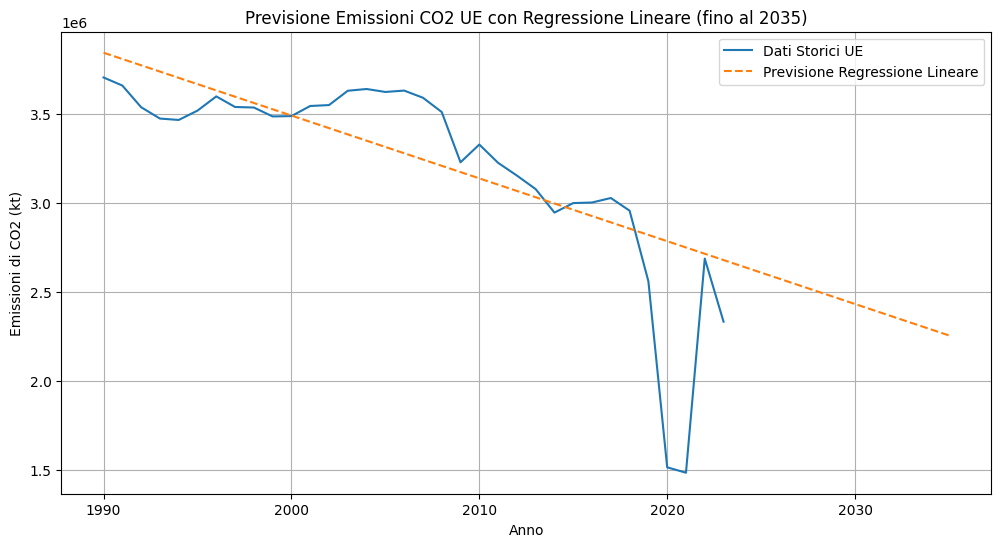

In [ ]:
# Inizializza e addestra il modello di regressione lineare
linear_model = LinearRegression()
linear_model.fit(X_train_np, y_train_np)

# Effettua previsioni sui dati di test
y_pred_linear = linear_model.predict(X_test_np)

# Valuta il modello
mse_linear = mean_squared_error(y_test_np, y_pred_linear)
print(f"Mean Squared Error (Regressione Lineare): {mse_linear:.2f}")

# Previsione fino al 2035
years_future = np.arange(X['Year'].min(), 2036).reshape(-1, 1) # Inizia dall'anno minimo presente nel dataset
co2_pred_linear = linear_model.predict(years_future)

# Crea un DataFrame per le previsioni di regressione lineare
df_pred_linear = pd.DataFrame({
    'Year': years_future.flatten(),
    'CO2 Emissions (kt)': co2_pred_linear
})

# Visualizza i risultati
plt.figure(figsize=(12, 6))
sns.lineplot(data=eu_total_co2_yearly, x='Year', y='CO2 Emissions (kt)', label='Dati Storici UE')
sns.lineplot(data=df_pred_linear, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Lineare', linestyle='--')
plt.title('Previsione Emissioni CO2 UE con Regressione Lineare (fino al 2035)')
plt.xlabel('Anno')
plt.ylabel('Emissioni di CO2 (kt)')
plt.grid(True)
plt.legend()
plt.show()

### 6. Modello di Regressione Polinomiale

Ora implementiamo un modello di regressione polinomiale per vedere se un'approssimazione non lineare può migliorare le previsioni. Useremo un grado polinomiale per trasformare le feature prima di applicare la regressione lineare.

Mean Squared Error (Regressione Polinomiale, grado 2): 345447100532.76


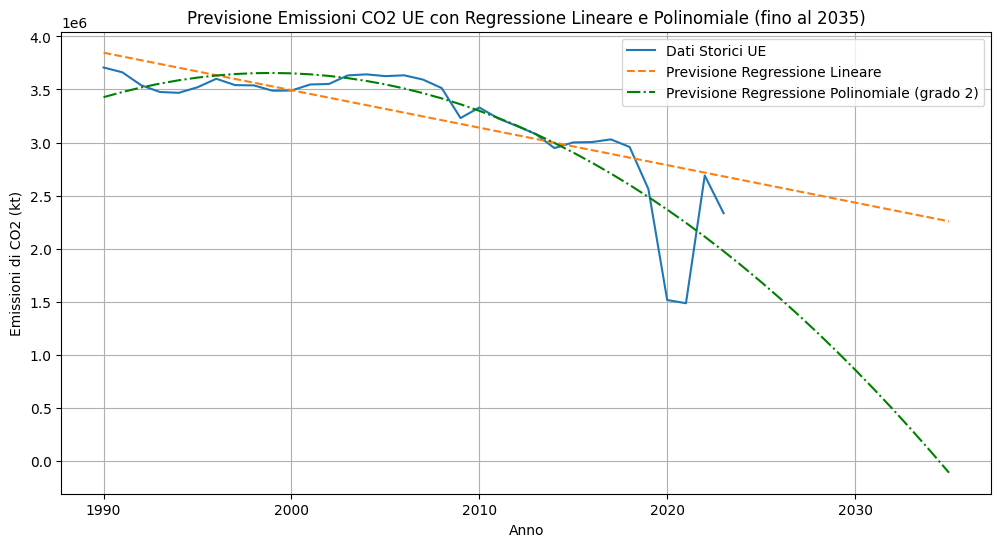

In [ ]:
# Inizializza il trasformatore di feature polinomiali (grado 2 come punto di partenza)
polynomial_features = PolynomialFeatures(degree=2)
X_train_poly = polynomial_features.fit_transform(X_train_np)
X_test_poly = polynomial_features.transform(X_test_np)

# Inizializza e addestra il modello di regressione lineare sui feature polinomiali
polynomial_model = LinearRegression()
polynomial_model.fit(X_train_poly, y_train_np)

# Effettua previsioni sui dati di test
y_pred_poly = polynomial_model.predict(X_test_poly)

# Valuta il modello
mse_poly = mean_squared_error(y_test_np, y_pred_poly)
print(f"Mean Squared Error (Regressione Polinomiale, grado 2): {mse_poly:.2f}")

# Previsione fino al 2035
years_future_poly = polynomial_features.transform(years_future)
co2_pred_poly = polynomial_model.predict(years_future_poly)

# Crea un DataFrame per le previsioni di regressione polinomiale
df_pred_poly = pd.DataFrame({
    'Year': years_future.flatten(),
    'CO2 Emissions (kt)': co2_pred_poly
})

# Visualizza i risultati insieme ai dati storici e alla regressione lineare
plt.figure(figsize=(12, 6))
sns.lineplot(data=eu_total_co2_yearly, x='Year', y='CO2 Emissions (kt)', label='Dati Storici UE')
sns.lineplot(data=df_pred_linear, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Lineare', linestyle='--')
sns.lineplot(data=df_pred_poly, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Polinomiale (grado 2)', linestyle='-.', color='green')
plt.title('Previsione Emissioni CO2 UE con Regressione Lineare e Polinomiale (fino al 2035)')
plt.xlabel('Anno')
plt.ylabel('Emissioni di CO2 (kt)')
plt.grid(True)
plt.legend()
plt.show()

### 7. Preparazione Dati per LSTM

Per il modello LSTM, dobbiamo convertire i dati in una sequenza temporale. Scaleremo i dati e creeremo delle sequenze di input (lookback window) e output per il training.

In [ ]:
# Scaliamo i dati per l'LSTM
scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(eu_total_co2_yearly[['CO2 Emissions (kt)']])

# Funzione per creare dataset per LSTM
def create_lstm_dataset(dataset, look_back=1):
    X_lstm, Y_lstm = [], []
    for i in range(len(dataset) - look_back):
        a = dataset[i:(i + look_back), 0]
        X_lstm.append(a)
        Y_lstm.append(dataset[i + look_back, 0])
    return np.array(X_lstm), np.array(Y_lstm)

# Definisci il look_back window (es. 3 anni precedenti per prevedere il successivo)
look_back = 3
X_lstm, y_lstm = create_lstm_dataset(data_scaled, look_back)

# Reshape per LSTM: [samples, time_steps, features]
X_lstm = np.reshape(X_lstm, (X_lstm.shape[0], X_lstm.shape[1], 1))

# Dividi i dati scalati in training e test
# Consideriamo gli anni fino al 2020 per il training, e gli anni successivi per il test
# Dobbiamo allineare con l'indice originale del DataFrame eu_total_co2_yearly

# Trova l'indice corrispondente all'anno 2020 nel DataFrame originale
idx_2020 = eu_total_co2_yearly[eu_total_co2_yearly['Year'] == 2020].index[0]

# Il training set per LSTM dovrebbe finire prima del 2020 + look_back per avere dati consistenti.
# L'indice per lo split del dataset LSTM è più complesso a causa del 'look_back'.
# Se l'ultimo dato di training è il 2020 (indice idx_2020), allora l'output per il 2020 è previsto da dati precedenti.
# Quindi, il training set LSTM dovrebbe includere le sequenze che prevedono fino al 2020.
# Il testing set LSTM inizierà con la sequenza che prevede il 2021.

# Calcola lo split index per il dataset LSTM.
# Il primo elemento in y_lstm corrisponde all'anno (min_year + look_back).
# L'ultimo anno di training in y_lstm dovrebbe essere 2020.
# Indice dell'anno 2020 come target in y_lstm:
# `idx_split_lstm = training_cutoff_year - eu_total_co2_yearly['Year'].min()`

# Split index for LSTM data (where y_lstm corresponds to years from min_year + look_back)
min_lstm_year = eu_total_co2_yearly['Year'].min() + look_back

# L'ultimo anno incluso nel training target è training_cutoff_year
# Il numero di campioni di training LSTM sarà (training_cutoff_year - min_lstm_year + 1)

split_idx_lstm = training_cutoff_year - min_lstm_year + 1 # +1 perché è inclusivo

X_train_lstm = X_lstm[:split_idx_lstm]
y_train_lstm = y_lstm[:split_idx_lstm]
X_test_lstm = X_lstm[split_idx_lstm:]
y_test_lstm = y_lstm[split_idx_lstm:]

print(f"Dimensioni dati LSTM di training: X={X_train_lstm.shape}, y={y_train_lstm.shape}")
print(f"Dimensioni dati LSTM di testing: X={X_test_lstm.shape}, y={y_test_lstm.shape}")

Dimensioni dati LSTM di training: X=(28, 3, 1), y=(28,)
Dimensioni dati LSTM di testing: X=(3, 3, 1), y=(3,)


### 8. Modello LSTM

Costruiamo un modello LSTM (Long Short-Term Memory), una rete neurale ricorrente particolarmente adatta per le serie temporali, per prevedere le emissioni di CO2. Useremo i dati scalati e le sequenze create nel passaggio precedente.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
Mean Squared Error (LSTM): 560018012182.92


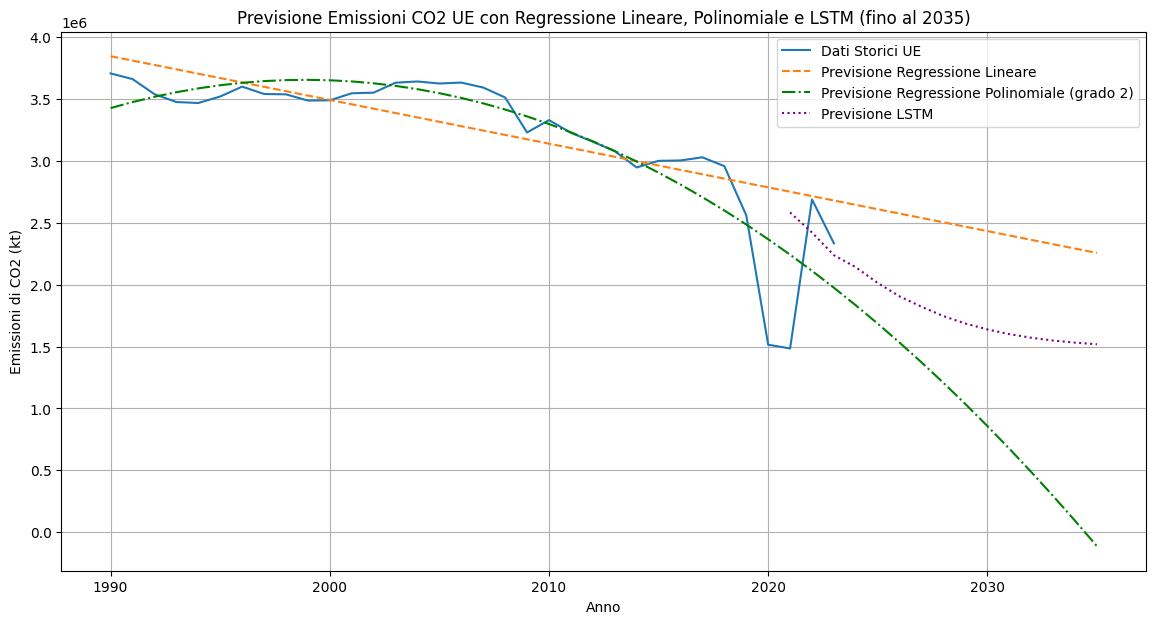

In [ ]:
# Costruisci il modello LSTM
lstm_model = Sequential()
lstm_model.add(LSTM(50, activation='relu', input_shape=(look_back, 1)))
lstm_model.add(Dense(1))
lstm_model.compile(optimizer='adam', loss='mean_squared_error')

# Addestra il modello
history = lstm_model.fit(X_train_lstm, y_train_lstm, epochs=100, batch_size=1, verbose=0)

# Effettua previsioni sui dati di test
y_pred_lstm_scaled = lstm_model.predict(X_test_lstm)

# Inverti la scalatura per ottenere i valori reali
y_pred_lstm = scaler.inverse_transform(y_pred_lstm_scaled)

# Valuta il modello
mse_lstm = mean_squared_error(scaler.inverse_transform(y_test_lstm.reshape(-1, 1)), y_pred_lstm)
print(f"Mean Squared Error (LSTM): {mse_lstm:.2f}")

# --- Previsione futura con LSTM fino al 2035 ---
# Partiamo dall'ultimo dato disponibile nel training set
last_train_sequence = X_train_lstm[-1]

# Crea una lista per memorizzare le previsioni future
future_predictions_scaled = []
current_sequence = last_train_sequence

# Prevedi fino al 2035
for i in range(2021, 2036):
    # Prevedi il prossimo valore
    next_prediction_scaled = lstm_model.predict(current_sequence.reshape(1, look_back, 1), verbose=0)[0, 0]
    future_predictions_scaled.append(next_prediction_scaled)

    # Aggiorna la sequenza corrente per la prossima previsione
    # Rimuovi il primo elemento e aggiungi la nuova previsione alla fine
    current_sequence = np.append(current_sequence[1:], next_prediction_scaled)
    current_sequence = current_sequence.reshape(look_back, 1) # Mantiene la forma corretta

# Inverti la scalatura delle previsioni future
future_predictions = scaler.inverse_transform(np.array(future_predictions_scaled).reshape(-1, 1))

# Crea un DataFrame per le previsioni LSTM
df_pred_lstm = pd.DataFrame({
    'Year': np.arange(2021, 2036),
    'CO2 Emissions (kt)': future_predictions.flatten()
})

# Visualizza i risultati
plt.figure(figsize=(14, 7))
sns.lineplot(data=eu_total_co2_yearly, x='Year', y='CO2 Emissions (kt)', label='Dati Storici UE')
sns.lineplot(data=df_pred_linear, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Lineare', linestyle='--')
sns.lineplot(data=df_pred_poly, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Polinomiale (grado 2)', linestyle='-.', color='green')
sns.lineplot(data=df_pred_lstm, x='Year', y='CO2 Emissions (kt)', label='Previsione LSTM', linestyle=':', color='purple')
plt.title('Previsione Emissioni CO2 UE con Regressione Lineare, Polinomiale e LSTM (fino al 2035)')
plt.xlabel('Anno')
plt.ylabel('Emissioni di CO2 (kt)')
plt.grid(True)
plt.legend()
plt.show()

### 9. Riepilogo e Confronto dei Modelli

Per concludere, possiamo confrontare le previsioni dei tre modelli e valutare quale sia il più adatto per questo tipo di serie storica.

--- Confronto MSE sui dati di test ---
Regressione Lineare MSE: 575271420638.17
Regressione Polinomiale (grado 2) MSE: 345447100532.76
LSTM MSE: 560018012182.92


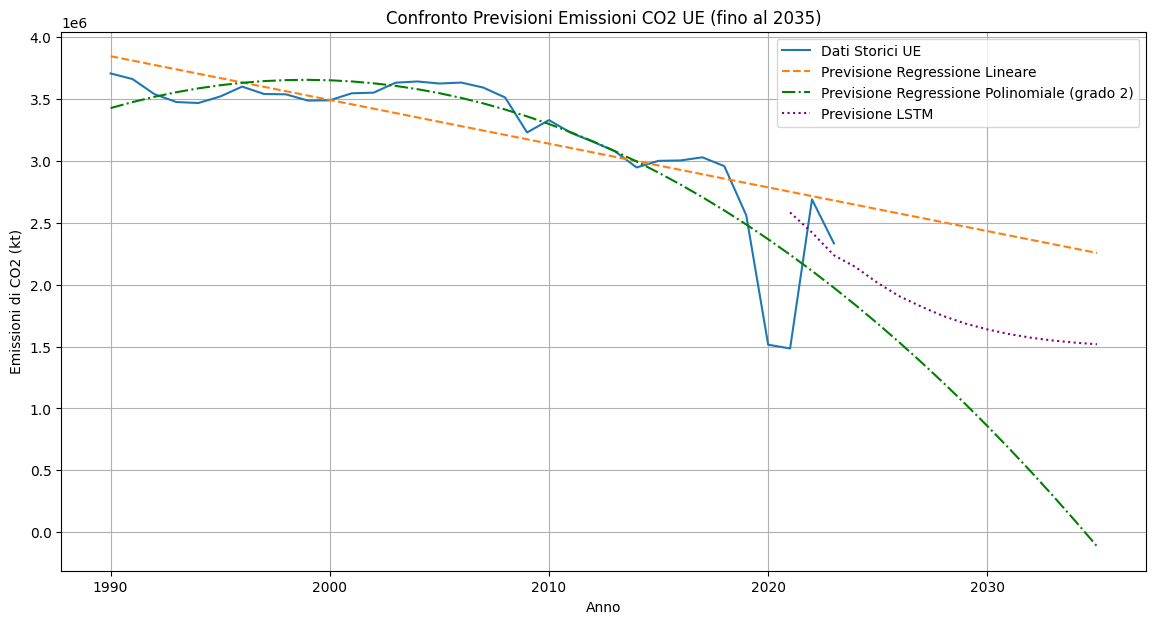

In [ ]:
print("--- Confronto MSE sui dati di test ---")
print(f"Regressione Lineare MSE: {mse_linear:.2f}")
print(f"Regressione Polinomiale (grado 2) MSE: {mse_poly:.2f}")
print(f"LSTM MSE: {mse_lstm:.2f}")

plt.figure(figsize=(14, 7))
sns.lineplot(data=eu_total_co2_yearly, x='Year', y='CO2 Emissions (kt)', label='Dati Storici UE')
sns.lineplot(data=df_pred_linear, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Lineare', linestyle='--')
sns.lineplot(data=df_pred_poly, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Polinomiale (grado 2)', linestyle='-.', color='green')
sns.lineplot(data=df_pred_lstm, x='Year', y='CO2 Emissions (kt)', label='Previsione LSTM', linestyle=':', color='purple')
plt.title('Confronto Previsioni Emissioni CO2 UE (fino al 2035)')
plt.xlabel('Anno')
plt.ylabel('Emissioni di CO2 (kt)')
plt.grid(True)
plt.legend()
plt.show()

### 6. Modello di Regressione Polinomiale

Ora implementiamo un modello di regressione polinomiale per vedere se un'approssimazione non lineare può migliorare le previsioni. Useremo un grado polinomiale per trasformare le feature prima di applicare la regressione lineare.

Mean Squared Error (Regressione Polinomiale, grado 2): 345447100532.76


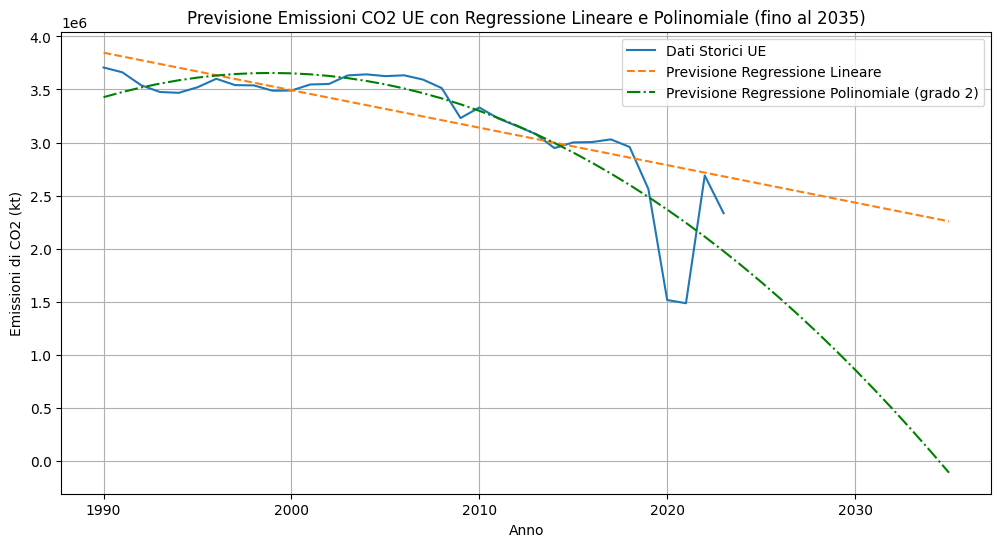

In [ ]:
# Inizializza il trasformatore di feature polinomiali (grado 2 come punto di partenza)
polynomial_features = PolynomialFeatures(degree=2)
X_train_poly = polynomial_features.fit_transform(X_train_np)
X_test_poly = polynomial_features.transform(X_test_np)

# Inizializza e addestra il modello di regressione lineare sui feature polinomiali
polynomial_model = LinearRegression()
polynomial_model.fit(X_train_poly, y_train_np)

# Effettua previsioni sui dati di test
y_pred_poly = polynomial_model.predict(X_test_poly)

# Valuta il modello
mse_poly = mean_squared_error(y_test_np, y_pred_poly)
print(f"Mean Squared Error (Regressione Polinomiale, grado 2): {mse_poly:.2f}")

# Previsione fino al 2035
years_future_poly = polynomial_features.transform(years_future)
co2_pred_poly = polynomial_model.predict(years_future_poly)

# Crea un DataFrame per le previsioni di regressione polinomiale
df_pred_poly = pd.DataFrame({
    'Year': years_future.flatten(),
    'CO2 Emissions (kt)': co2_pred_poly
})

# Visualizza i risultati insieme ai dati storici e alla regressione lineare
plt.figure(figsize=(12, 6))
sns.lineplot(data=eu_total_co2_yearly, x='Year', y='CO2 Emissions (kt)', label='Dati Storici UE')
sns.lineplot(data=df_pred_linear, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Lineare', linestyle='--')
sns.lineplot(data=df_pred_poly, x='Year', y='CO2 Emissions (kt)', label='Previsione Regressione Polinomiale (grado 2)', linestyle='-.', color='green')
plt.title('Previsione Emissioni CO2 UE con Regressione Lineare e Polinomiale (fino al 2035)')
plt.xlabel('Anno')
plt.ylabel('Emissioni di CO2 (kt)')
plt.grid(True)
plt.legend()
plt.show()

### 7. Preparazione Dati per LSTM

Per il modello LSTM, dobbiamo convertire i dati in una sequenza temporale. Scaleremo i dati e creeremo delle sequenze di input (lookback window) e output per il training.

In [ ]:
# Scaliamo i dati per l'LSTM
scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(eu_total_co2_yearly[['CO2 Emissions (kt)']])

# Funzione per creare dataset per LSTM
def create_lstm_dataset(dataset, look_back=1):
    X_lstm, Y_lstm = [], []
    for i in range(len(dataset) - look_back):
        a = dataset[i:(i + look_back), 0]
        X_lstm.append(a)
        Y_lstm.append(dataset[i + look_back, 0])
    return np.array(X_lstm), np.array(Y_lstm)

# Definisci il look_back window (es. 3 anni precedenti per prevedere il successivo)
look_back = 3
X_lstm, y_lstm = create_lstm_dataset(data_scaled, look_back)

# Reshape per LSTM: [samples, time_steps, features]
X_lstm = np.reshape(X_lstm, (X_lstm.shape[0], X_lstm.shape[1], 1))

# Dividi i dati scalati in training e test
# Consideriamo gli anni fino al 2020 per il training, e gli anni successivi per il test
# Dobbiamo allineare con l'indice originale del DataFrame eu_total_co2_yearly

# Trova l'indice corrispondente all'anno 2020 nel DataFrame originale
idx_2020 = eu_total_co2_yearly[eu_total_co2_yearly['Year'] == 2020].index[0]

# Il training set per LSTM dovrebbe finire prima del 2020 + look_back per avere dati consistenti
# L'indice per lo split del dataset LSTM è più complesso a causa del 'look_back'
# Se l'ultimo dato di training è il 2020 (indice idx_2020), allora l'output per il 2020 è previsto da dati precedenti.
# Quindi, il training set LSTM dovrebbe includere le sequenze che prevedono fino al 2020.
# Il testing set LSTM inizierà con la sequenza che prevede il 2021.

# Calcola lo split index per il dataset LSTM
# Se l'ultimo anno di training per i modelli precedenti era 2020, e il look_back è 3,
# la sequenza [2018, 2019, 2020] prevede il 2021. Quindi l'ultimo elemento del training LSTM
# dovrebbe essere quello che prevede il 2020.

# L'indice nel dataset LSTM corrisponde all'anno target - eu_total_co2_yearly['Year'].min() - look_back
# Per un target year di 2020, l'indice nel dataset LSTM è: 2020 - 1990 - 3 = 27
# In realtà l'indice per il training_cutoff_year nel dataset LSTM è l'indice nel dataset LSTM del valore TARGET (y_lstm) = training_cutoff_year
# Il training_cutoff_year è 2020. Quindi il target 2020 avrà X_lstm che include gli anni fino a 2019.
# Il numero di campioni in X_lstm è len(dataset) - look_back

# Anni target per training: 1990 + look_back a 2020
# Anni target per testing: 2021 a 2023

# Calcoliamo l'indice di split.
# Il primo elemento in y_lstm corrisponde all'anno (min_year + look_back).
# L'ultimo anno di training in y_lstm dovrebbe essere 2020.
# Indice dell'anno 2020 come target in y_lstm:
# `idx_split_lstm = training_cutoff_year - eu_total_co2_yearly['Year'].min()`

# Split index for LSTM data (where y_lstm corresponds to years from min_year + look_back)
min_lstm_year = eu_total_co2_yearly['Year'].min() + look_back

# L'ultimo anno incluso nel training target è training_cutoff_year
# Il numero di campioni di training LSTM sarà (training_cutoff_year - min_lstm_year + 1)

split_idx_lstm = training_cutoff_year - min_lstm_year + 1 # +1 perché è inclusivo

X_train_lstm = X_lstm[:split_idx_lstm]
y_train_lstm = y_lstm[:split_idx_lstm]
X_test_lstm = X_lstm[split_idx_lstm:]
y_test_lstm = y_lstm[split_idx_lstm:]

print(f"Dimensioni dati LSTM di training: X={X_train_lstm.shape}, y={y_train_lstm.shape}")
print(f"Dimensioni dati LSTM di testing: X={X_test_lstm.shape}, y={y_test_lstm.shape}")

Dimensioni dati LSTM di training: X=(28, 3, 1), y=(28,)
Dimensioni dati LSTM di testing: X=(3, 3, 1), y=(3,)
